# Program 20: Relapse-Guard, the final method

**What:** combine the best pieces into one clean, configurable method.

**How:** one config file selects buffer purge, head reset, guard type (penalty or projection), k and λ. The same script runs every stream and saves metrics to `results/`.

**Why:** Phase F needs one reliable method that runs every experiment the same way.

**Understanding note:** each part has a job. Purge stops buffer leakage, head reset stops output relapse, and the guard stops feature relapse. The paper's ablations will prove each job.

**Done when:** one command reproduces your best result on a fixed seed.

## Where this fits (for a first-time reader)

Programs 17–19 tested the pieces one at a time. This program:
1. **picks the best guard** from programs 18 and 19 with a fixed rule (written below, decided before looking at the numbers);
2. writes it as **one config file**, `results/configs/relapse_guard.json`;
3. runs it with **one command**, `python -m common.clu results/configs/relapse_guard.json`, and checks that it reproduces the chosen run;
4. runs the final method and the simple-fixes baseline on program 11's **worst-case stream** (`L0 → U0 → L1 … L9`, 9 tasks learned after forgetting), the hardest case for relapse;
5. puts every method of Phases D–E in **one table**.

The method lives in `common/clu.py`. Each switch in the config is one piece:

| Switch | Piece | Job |
|---|---|---|
| `purge_buffer` | delete forgotten classes from the DER++ buffer | stops buffer leakage (program 15) |
| `head_reset` | fresh, frozen head rows for forgotten classes | stops output relapse (program 17) |
| `mask_forgotten_logits` | leave forgotten columns out of DER++ logit replay | stops relapse through stored logits (program 12's "carriers") |
| `guard`, `guard_lambda`, `k`, `signature` | penalty or projection on the forgotten directions | stops feature relapse (programs 18, 19) |

## 1. Setup and the selection rule

**Rule:** among the guard runs of programs 18 and 19 on `task15_seed0`, keep those whose RA (task-IL) is at most **3 points** below program 17's simple fixes. Of those, choose the one with the **lowest probe on forgotten tasks at the end** (the features know the least about what was forgotten). If none qualifies, use the simple fixes alone.

**Time:** the one-command run about 15 minutes, the worst-case stream about 12 minutes per method (2 methods).

In [1]:
import gc, json, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.derpp, common.badteacher, common.features, common.metrics, common.stream, common.clu
for module in (common.utils, common.data, common.models, common.derpp, common.badteacher, common.features, common.metrics, common.stream, common.clu):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np

from common.clu import load_result, make_config, run_or_load
from common.data import SplitCIFAR100
from common.metrics import all_metrics, item_view
from common.utils import RESULTS_DIR, log_run

# Program 14's retrain model: probe accuracy on each task when the task was NEVER learned (the target).
RETRAIN_PROBE = None
for line in (RESULTS_DIR / "runs.jsonl").read_text().splitlines():
    entry = json.loads(line)
    if entry["program"] == "14_feature_probe":
        RETRAIN_PROBE = np.array(entry["results"]["probe"]["retrain"])

def metrics_row(res, kind="til"):
    s = res["summary"][kind]
    return s["RA"], s["FA"], s["Spill"], s["Relapse"]


def show_table(runs, retrain_probe=None):
    """runs: name -> result dict. Prints the four metrics and the probe numbers on forgotten items."""
    print(f"{'run':>28} | {'RA':>6} {'FA':>6} {'Spill':>6} {'Relapse':>7} | {'RA cil':>6} {'FA cil':>6} | "
          f"{'probe: before':>13} {'after U':>8} {'end':>6} {'peak rise':>9}")
    for name, res in runs.items():
        ra, fa, sp, rel = metrics_row(res, "til")
        rac, fac, _, _ = metrics_row(res, "cil")
        p = res["summary"].get("probe")
        ptxt = (f"{p['before']*100:12.1f}% {p['after_U']*100:7.1f}% {p['end']*100:5.1f}% {p['peak_rise']*100:+8.1f}"
                if p else f"{'-':>13} {'-':>8} {'-':>6} {'-':>9}")
        print(f"{name:>28} | {ra*100:5.1f}% {fa*100:5.1f}% {sp*100:6.1f} {rel*100:7.1f} | {rac*100:5.1f}% {fac*100:5.1f}% | {ptxt}")
    if retrain_probe is not None:
        print(f"\nretrain model (program 14), probe on the same forgotten tasks: {retrain_probe*100:.1f}%  (the target)")
    print("RA/FA/Spill/Relapse: task-IL (chance 10%); 'cil' = class-IL. Probe: 10-way on each forgotten task's features.")


def plot_forgotten(runs, title, file, show_retrain=True):
    """Head task-IL accuracy and feature probe of the forgotten items after every request."""
    import warnings
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
    for name, res in runs.items():
        acc, learned, forgotten, rows = item_view(res, "til")
        head = [np.nanmean(acc[r, forgotten[r]]) * 100 if forgotten[r].any() else np.nan for r in range(len(acc))]
        line, = axes[0].plot(head, marker="o", ms=3, label=name)
        if "probe" in res:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                axes[1].plot(np.nanmean(res["probe"], axis=1) * 100, marker="o", ms=3, color=line.get_color(), label=name)
    labels = [str(s) for s in next(iter(runs.values()))["requests"]]
    for ax in axes:
        ax.set_xticks(range(len(labels)), labels, rotation=45, fontsize=8)
    axes[0].axhline(10, color="gray", ls="--", lw=1, label="chance")
    axes[0].set(title="Head: task-IL accuracy of forgotten tasks (average, %)", ylabel="accuracy (%)", ylim=(0, 100))
    axes[1].set(title="Features: probe accuracy of forgotten tasks (average, %)", ylabel="probe accuracy (%)")
    if show_retrain and RETRAIN_PROBE is not None:
        axes[1].axhline(RETRAIN_PROBE[[int(s[1:]) for s in labels if s[0] == "U"]].mean() * 100,
                        color="green", ls=":", lw=1.5, label="retrain (target)")
    for ax in axes:
        ax.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / file, dpi=120)
    plt.show()

import subprocess

CANDIDATES = ["18_guard_l0.1", "18_guard_l1", "18_guard_l10", "19_projection"]
base = load_result("17_simple_fixes")
if base is None:
    raise FileNotFoundError("run program 17 first")
ra_base = base["summary"]["til"]["RA"]

print(f"simple fixes (17): RA {ra_base*100:.1f}%, probe end {base['summary']['probe']['end']*100:.1f}%")
choice, best = "17_simple_fixes", None
for name in CANDIDATES:
    r = load_result(name)
    if r is None:
        print(f"{name}: not found, skipped")
        continue
    ra, pe = r["summary"]["til"]["RA"], r["summary"]["probe"]["end"]
    ok = ra >= ra_base - 0.03
    print(f"{name:>16}: RA {ra*100:5.1f}%  probe end {pe*100:5.1f}%  {'qualifies' if ok else 'RA too low'}")
    if ok and (best is None or pe < best):
        choice, best = name, pe
print(f"\nchosen: {choice}")
chosen = load_result(choice)

simple fixes (17): RA 76.9%, probe end 76.1%
   18_guard_l0.1: RA  76.3%  probe end  76.8%  qualifies
     18_guard_l1: RA  77.5%  probe end  75.4%  qualifies
    18_guard_l10: RA  76.2%  probe end  76.2%  qualifies
   19_projection: RA  76.9%  probe end  75.3%  qualifies

chosen: 19_projection


## 2. The config file

The chosen run's config, renamed, is written to `results/configs/relapse_guard.json`. That file is the whole method.

In [2]:
final_cfg = dict(chosen["config"])
final_cfg["name"] = "20_final_task15_seed0"
cfg_dir = RESULTS_DIR / "configs"
cfg_dir.mkdir(exist_ok=True)
cfg_path = cfg_dir / "relapse_guard.json"
cfg_path.write_text(json.dumps(final_cfg, indent=1))
print(cfg_path.read_text())
SETTINGS = {"chosen_from": choice, "config": final_cfg}

{
 "name": "20_final_task15_seed0",
 "stream": "task15_seed0",
 "seed": 0,
 "workers": 2,
 "epochs": 5,
 "lr": 0.03,
 "batch_size": 32,
 "buffer_size": 2000,
 "replay_batch": 32,
 "alpha": 0.5,
 "beta": 0.5,
 "unlearn_lr": 0.0001,
 "unlearn_steps": 50,
 "forget_batch": 64,
 "retain_batch": 192,
 "forget_data": "all",
 "min_forget": 64,
 "bad_teacher_seed": 0,
 "purge_buffer": true,
 "head_reset": true,
 "mask_forgotten_logits": true,
 "guard": "projection",
 "guard_lambda": 1.0,
 "k": 5,
 "signature": "specific",
 "signature_images": 1000,
 "probe_folds": 5
}


## 3. One command

The cell runs exactly what you would type in a terminal from the project folder:

```
python -m common.clu results/configs/relapse_guard.json
```

It is a separate process, so it starts from nothing (no state from this notebook). Its numbers are then compared with the chosen run's. GPU arithmetic isn't perfectly deterministic, so expect agreement within a point or so, not to the last digit.

In [3]:
start = time.time()
proc = subprocess.run([sys.executable, "-m", "common.clu", str(cfg_path.relative_to(ROOT))],
                      cwd=ROOT, capture_output=True, text=True)
print("\n".join(proc.stdout.splitlines()[:40]))
if proc.returncode != 0:
    print(proc.stderr[-3000:])
    raise RuntimeError("the one-command run failed")
print(f"... finished in {(time.time() - start) / 60:.1f} min")

final = load_result("20_final_task15_seed0")
print(f"\n{'':>14} {'RA':>7} {'FA':>7} {'Spill':>6} {'Relapse':>8} {'probe end':>10}")
for name, r in [(f"chosen ({choice})", chosen), ("one command", final)]:
    s = r["summary"]
    print(f"{name:>14} {s['til']['RA']*100:6.1f}% {s['til']['FA']*100:6.1f}% {s['til']['Spill']*100:6.1f} "
          f"{s['til']['Relapse']*100:8.1f} {s['probe']['end']*100:9.1f}%")

[  0] L5   kept  67.5%  train acc 65.3%  (82s)
[  1] L2   kept  72.2%  train acc 78.4%  (163s)
[  2] L3   kept  73.8%  train acc 74.6%  (244s)
[  3] L4   kept  74.9%  train acc 82.3%  (325s)
[  4] U5   kept  77.0%  forgot head  10.3%  probe  70.8%  forget imgs 5000 (494 in buffer), deleted 494  (353s)
[  5] L9   kept  77.2%  forgot head  13.4%  probe  75.0%  train acc 86.2%  (438s)
[  6] L0   kept  77.4%  forgot head   4.9%  probe  72.5%  train acc 80.4%  (522s)
[  7] U3   kept  78.3%  forgot head  11.0%  probe  73.1%  forget imgs 5000 (326 in buffer), deleted 326  (551s)
[  8] U2   kept  76.6%  forgot head   9.9%  probe  75.2%  forget imgs 5000 (359 in buffer), deleted 359  (579s)
[  9] L8   kept  79.2%  forgot head  16.1%  probe  75.0%  train acc 90.9%  (663s)
[ 10] U8   kept  75.0%  forgot head  12.3%  probe  76.0%  forget imgs 5000 (857 in buffer), deleted 857  (691s)
[ 11] L7   kept  78.1%  forgot head  12.8%  probe  75.9%  train acc 93.4%  (776s)
[ 12] L6   kept  77.8%  forgot he

## 4. The worst case: forget first, then learn 9 tasks

Program 12 on `handmade_worst` saw task 0 go from 10% back up to 29.7% after one new task. Here the simple fixes and the final method run on the same stream. (There is no retrain target for this stream: program 14's retrain model was built for `task15_seed0`, where task 0 was a kept task. Compare the probe with its value right after `U0` instead.) In this stream the `U0` comes right after the first task, so the buffer holds no retain data; the specific signature then falls back to the plain one.

In [4]:
data = SplitCIFAR100(seed=0, batch_size=32, num_workers=2)
worst = {}
for label, cfg in [("simple fixes", make_config(name="20_fixes_handmade_worst", stream="handmade_worst",
                                                 head_reset=True, mask_forgotten_logits=True)),
                   ("Relapse-Guard", {**final_cfg, "name": "20_final_handmade_worst", "stream": "handmade_worst"})]:
    print(f"===== {label}")
    worst[label] = run_or_load(cfg, data)
del data
gc.collect()

===== simple fixes


[  0] L0   kept  52.9%  train acc 61.2%  (78s)


[  1] U0   kept   -    forgot head  10.0%  probe  31.2%  forget imgs 5000 (2000 in buffer), deleted 2000  (92s)


[  2] L1   kept  61.3%  forgot head   9.1%  probe  53.8%  train acc 80.9%  (171s)


[  3] L2   kept  77.8%  forgot head   7.3%  probe  57.5%  train acc 79.9%  (250s)


[  4] L3   kept  77.5%  forgot head  11.5%  probe  58.8%  train acc 75.5%  (329s)


... (15 outputs left out)

[  8] L7   kept  79.3%  forgot head  11.2%  probe  64.1%  train acc 90.5%  (650s)


[  9] L8   kept  78.3%  forgot head   7.4%  probe  63.2%  train acc 90.8%  (730s)


[ 10] L9   kept  78.8%  forgot head   9.4%  probe  65.1%  train acc 91.1%  (808s)


0

                         run |     RA     FA  Spill Relapse | RA cil FA cil | probe: before  after U    end peak rise
             12 (program 12) |  77.3%  19.6%    0.0     9.6 |  42.3%   0.0% |             -        -      -         -
                simple fixes |  79.4%  14.0%    0.0     4.0 |  42.0%   0.0% |         55.3%    31.2%  67.4%    +36.2
               Relapse-Guard |  78.8%   9.4%    0.0     0.5 |  40.2%   0.0% |         56.8%    28.9%  65.1%    +36.2
RA/FA/Spill/Relapse: task-IL (chance 10%); 'cil' = class-IL. Probe: 10-way on each forgotten task's features.


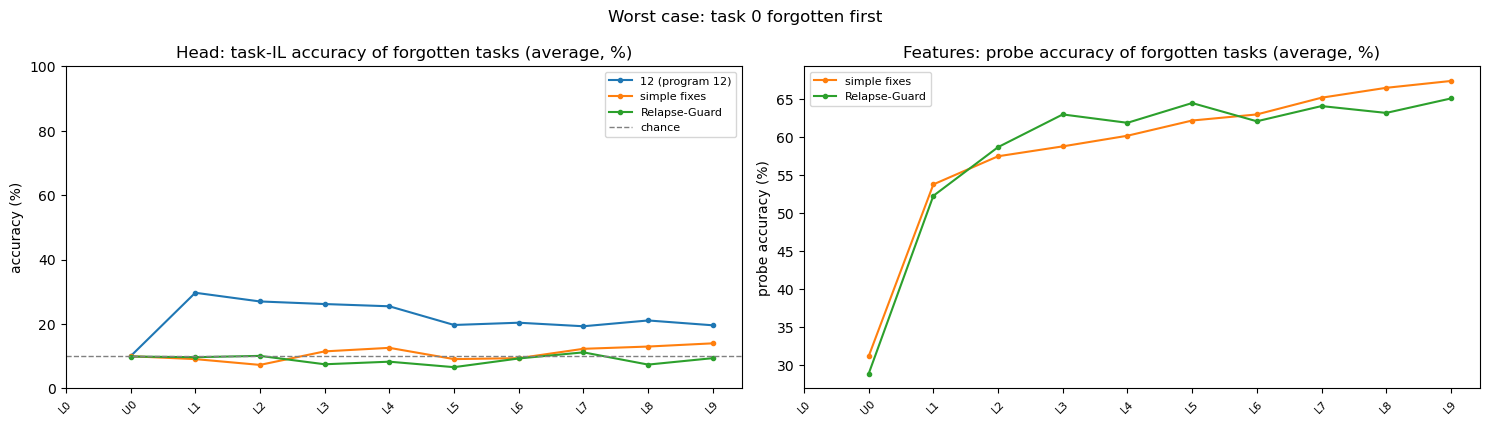

In [5]:
runs_worst = {}
p12 = RESULTS_DIR / "12_handmade_worst.npz"
if p12.exists():
    d = np.load(p12)
    r12 = {k: d[k] for k in d.files}
    r12["level"] = str(r12["level"])
    r12["summary"] = {kind: all_metrics(*item_view(r12, kind)) for kind in ("til", "cil")}
    runs_worst["12 (program 12)"] = r12
runs_worst.update(worst)
# No retrain target here: program 14's retrain model was built for task15_seed0, where task 0 was KEPT (learned).
show_table(runs_worst)
plot_forgotten(runs_worst, "Worst case: task 0 forgotten first", "20_worst_case.png", show_retrain=False)

## 5. Everything in one table (`task15_seed0`)

Every method of Phases D–E on the same stream. Program 12 has no probe numbers (not measured then).

In [6]:
all_runs = {}
p12 = RESULTS_DIR / "12_task15_seed0.npz"
if p12.exists():
    d = np.load(p12)
    r12 = {k: d[k] for k in d.files}
    r12["level"] = str(r12["level"])
    r12["summary"] = {kind: all_metrics(*item_view(r12, kind)) for kind in ("til", "cil")}
    all_runs["12 BadTeacher (naive)"] = r12
for label, name in [("17 BadTeacher + purge", "17_badteacher_only"), ("17 simple fixes", "17_simple_fixes"),
                    ("18 penalty λ=0.1", "18_guard_l0.1"), ("18 penalty λ=1", "18_guard_l1"),
                    ("18 penalty λ=10", "18_guard_l10"), ("19 projection", "19_projection"),
                    ("20 Relapse-Guard", "20_final_task15_seed0")]:
    r = load_result(name)
    if r is not None:
        all_runs[label] = r
forgotten_tasks = [int(s[1:]) for s in final["requests"] if str(s)[0] == "U"]
show_table(all_runs, RETRAIN_PROBE[forgotten_tasks].mean() if RETRAIN_PROBE is not None else None)

                         run |     RA     FA  Spill Relapse | RA cil FA cil | probe: before  after U    end peak rise
       12 BadTeacher (naive) |  79.6%  27.9%    6.0    18.1 |  50.8%   0.2% |             -        -      -         -
       17 BadTeacher + purge |  77.1%  33.3%    8.1    21.1 |  54.9%   1.9% |         78.8%    76.5%  75.9%     +1.9
             17 simple fixes |  76.9%  11.7%    7.9     2.7 |  54.0%   0.0% |         79.0%    77.5%  76.1%     +1.4
            18 penalty λ=0.1 |  76.3%  10.2%    9.4     2.3 |  55.3%   0.0% |         78.9%    78.1%  76.8%     +1.2
              18 penalty λ=1 |  77.5%   9.9%    7.7     1.4 |  56.8%   0.0% |         78.5%    77.0%  75.4%     +1.2
             18 penalty λ=10 |  76.2%  12.0%    9.5     5.2 |  54.4%   0.0% |         78.9%    78.6%  76.2%     +0.6
               19 projection |  76.9%  10.0%    9.1     2.1 |  55.3%   0.0% |         78.4%    77.2%  75.3%     +0.6
            20 Relapse-Guard |  76.1%   9.6%    9.4     2.8 | 

## 6. Log the run

In [7]:
log_run("20_relapse_guard_full", SETTINGS,
        {"one_command": final["summary"], "chosen": chosen["summary"],
         "worst_case": {k: v["summary"] for k, v in worst.items()}})
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. Which guard was chosen, and by how much did it beat the simple fixes on the probe? What did it cost in RA?
2. Did the one-command run reproduce the chosen run? How close?
3. Worst case: did the final method keep task 0 forgotten (head and features) through 9 later tasks, compared with program 12 and the simple fixes?
4. In the full table, which piece did the most work: purge, head reset, or the guard? What would the paper's ablation table show?
5. What is still missing before Phase F (more seeds, class-level streams, other datasets)?